
# Lab 8: Monte Carlo Markov Chain (MCMC)


Ross An Miranda
1034988497


**Exercise 1**:

* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  


Contenido:
1. Integración Monte Carlo (1D y 2D), con dos estimadores distintos: *valor medio* y *acierto–fallo* (hit or miss).
2. Resumen del modelo de Ising en 1D, 2D y 3D.
3. Simulación del modelo de Ising 2D con Metrópolis (barrido de tablero de ajedrez) y curvas $M(H)$ para $T = 5, 10, 15$ K.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
import time

rng = np.random.default_rng(8)          # generador único y reproducible
plt.rcParams.update({"figure.figsize": (7.5, 4.5), "axes.grid": True, "grid.alpha": 0.3})

## Ejercicio 1 — Integración Monte Carlo

Si $X_i \sim U(a,b)$, entonces $\displaystyle I=\int_a^b f(x)\,dx = (b-a)\,\mathbb{E}[f(X)] \approx \frac{b-a}{N}\sum_{i=1}^N f(X_i)$,
con incertidumbre $\sigma_I \approx (b-a)\,s_f/\sqrt{N}$ ($s_f$ = desviación estándar muestral de $f(X_i)$).

El método **acierto–fallo** lanza puntos uniformes en el rectángulo $[a,b]\times[0,f_{\max}]$ y cuenta la fracción $p$ que cae bajo la curva: $I \approx p\,(b-a)\,f_{\max}$, con $\sigma_I = (b-a)f_{\max}\sqrt{p(1-p)/N}$.

### 1.1  $\int_0^4 \sqrt{x}\,dx$

Resultado analítico: $\displaystyle \int_0^4 x^{1/2}dx = \tfrac{2}{3}x^{3/2}\Big|_0^4 = \tfrac{2}{3}\cdot 8 = \tfrac{16}{3} \approx 5.3333$.

In [2]:
def mc_valor_medio(f, a, b, N):
    x = rng.uniform(a, b, N)
    fx = f(x)
    I = (b - a) * fx.mean()
    err = (b - a) * fx.std(ddof=1) / np.sqrt(N)
    return I, err

def mc_acierto_fallo(f, a, b, fmax, N):
    x = rng.uniform(a, b, N)
    y = rng.uniform(0, fmax, N)
    p = np.mean(y <= f(x))
    caja = (b - a) * fmax
    return caja * p, caja * np.sqrt(p * (1 - p) / N)

f1 = np.sqrt
a, b = 0.0, 4.0
I1_exacta = 16 / 3
I1_quad = integrate.quad(f1, a, b)[0]

print(f"Analítica : {I1_exacta:.6f}")
print(f"scipy.quad: {I1_quad:.6f}\n")
print(f"{'N':>9} | {'valor medio':>20} | {'acierto-fallo':>20}")
for N in [10**2, 10**3, 10**4, 10**5, 10**6]:
    Iv, ev = mc_valor_medio(f1, a, b, N)
    Ih, eh = mc_acierto_fallo(f1, a, b, 2.0, N)
    print(f"{N:>9} | {Iv:8.5f} ± {ev:8.5f} | {Ih:8.5f} ± {eh:8.5f}")

Analítica : 5.333333
scipy.quad: 5.333333

        N |          valor medio |        acierto-fallo
      100 |  5.12957 ±  0.16218 |  5.52000 ±  0.36999
     1000 |  5.30237 ±  0.05699 |  5.27200 ±  0.11993
    10000 |  5.36263 ±  0.01870 |  5.34240 ±  0.03768
   100000 |  5.33860 ±  0.00595 |  5.33912 ±  0.01192
  1000000 |  5.33490 ±  0.00189 |  5.33198 ±  0.00377


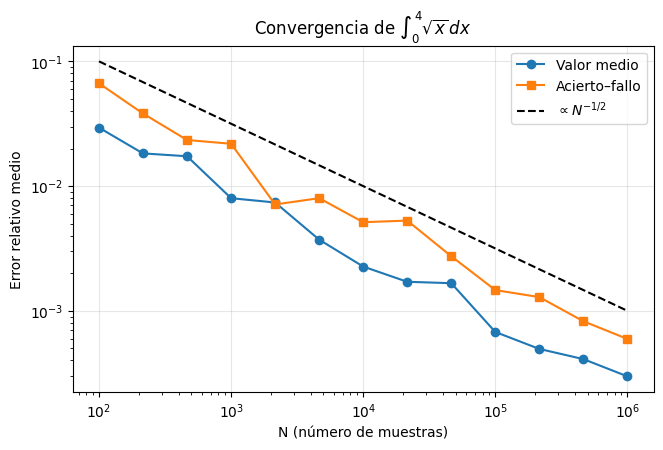

In [3]:
# Convergencia: error relativo vs N (promediado sobre varias repeticiones)
Ns = np.logspace(2, 6, 13).astype(int)
rep = 30
err_vm = [np.mean([abs(mc_valor_medio(f1, a, b, N)[0] - I1_exacta) for _ in range(rep)]) for N in Ns]
err_af = [np.mean([abs(mc_acierto_fallo(f1, a, b, 2.0, N)[0] - I1_exacta) for _ in range(rep)]) for N in Ns]

plt.loglog(Ns, np.array(err_vm) / I1_exacta, "o-", label="Valor medio")
plt.loglog(Ns, np.array(err_af) / I1_exacta, "s-", label="Acierto–fallo")
plt.loglog(Ns, 1 / np.sqrt(Ns), "k--", label=r"$\propto N^{-1/2}$")
plt.xlabel("N (número de muestras)"); plt.ylabel("Error relativo medio")
plt.title(r"Convergencia de $\int_0^4\sqrt{x}\,dx$")
plt.legend(); plt.show()

Ambos estimadores convergen como $N^{-1/2}$, independiente de la dimensión. El de valor medio tiene menor varianza
(usa el valor de $f$ en cada punto, no sólo un bit de información “dentro/fuera”), por eso su curva queda por debajo.

### 1.2  $\displaystyle\int_{0}^{2}\int_{0}^{1} x\,y^2\,dy\,dx$

Analítico (la integral es separable): $\left(\int_0^2 x\,dx\right)\left(\int_0^1 y^2 dy\right) = 2\cdot\tfrac13 = \tfrac23 \approx 0.6667$.

En 2D: $I \approx A\,\langle f(X,Y)\rangle$ con $A = (2-0)(1-0) = 2$ el área de la caja.

In [4]:
def mc_2d(f, xlim, ylim, N):
    x = rng.uniform(*xlim, N)
    y = rng.uniform(*ylim, N)
    area = (xlim[1] - xlim[0]) * (ylim[1] - ylim[0])
    fxy = f(x, y)
    return area * fxy.mean(), area * fxy.std(ddof=1) / np.sqrt(N)

f2 = lambda x, y: x * y**2
I2_exacta = 2 / 3
I2_dbl = integrate.dblquad(lambda y, x: x * y**2, 0, 2, 0, 1)[0]   # scipy integra primero en y

print(f"Analítica    : {I2_exacta:.6f}")
print(f"scipy.dblquad: {I2_dbl:.6f}\n")
for N in [10**2, 10**3, 10**4, 10**5, 10**6]:
    I, e = mc_2d(f2, (0, 2), (0, 1), N)
    print(f"N = {N:>8}:  I = {I:.5f} ± {e:.5f}   |error| = {abs(I - I2_exacta):.2e}")

Analítica    : 0.666667
scipy.dblquad: 0.666667

N =      100:  I = 0.62118 ± 0.07489   |error| = 4.55e-02
N =     1000:  I = 0.63108 ± 0.02425   |error| = 3.56e-02
N =    10000:  I = 0.65820 ± 0.00787   |error| = 8.47e-03
N =   100000:  I = 0.66525 ± 0.00249   |error| = 1.41e-03
N =  1000000:  I = 0.66580 ± 0.00079   |error| = 8.68e-04


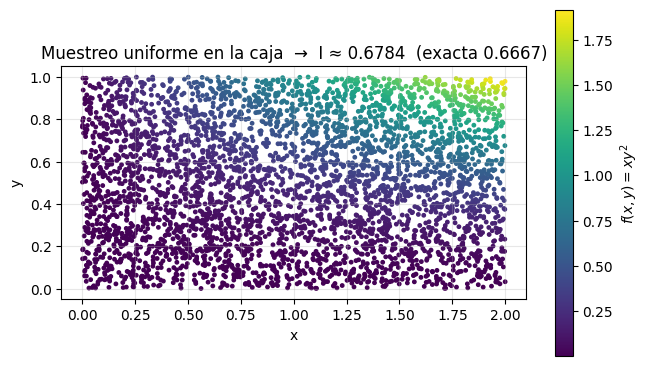

In [5]:
# Visualización de los puntos de muestreo coloreados por el valor de f(x,y)
N = 4000
x = rng.uniform(0, 2, N); y = rng.uniform(0, 1, N)
sc = plt.scatter(x, y, c=f2(x, y), s=6, cmap="viridis")
plt.colorbar(sc, label=r"$f(x,y)=xy^2$")
plt.xlabel("x"); plt.ylabel("y")
plt.title(f"Muestreo uniforme en la caja  →  I ≈ {2 * f2(x, y).mean():.4f}  (exacta 0.6667)")
plt.gca().set_aspect("equal"); plt.show()

## Ejercicio 2 — El modelo de Ising en 1D, 2D y 3D

El modelo de Ising describe una red de “espines” $s_i=\pm1$ (momentos magnéticos que sólo pueden apuntar arriba o abajo)
con hamiltoniano

$$\mathcal{H} = -J\sum_{\langle i,j\rangle} s_i s_j \;-\; \mu H \sum_i s_i ,$$

donde $\langle i,j\rangle$ recorre los pares de primeros vecinos, $J$ es la constante de intercambio ($J>0$ favorece
alineación → ferromagnetismo; $J<0$ antiferromagnetismo) y $H$ es el campo externo. En el ensamble canónico la
probabilidad de una configuración es $P(\{s\}) \propto e^{-\mathcal{H}/k_BT}$; la competencia entre energía (orden) y
entropía (desorden) determina si existe magnetización espontánea.

* **1D (cadena).** Resuelto por Ernst Ising (1925) con la matriz de transferencia. La energía libre es analítica
  para toda $T>0$: **no hay transición de fase**. Romper la cadena en dos dominios cuesta sólo $2J$, mientras la entropía
  de colocar esa pared crece como $k_BT\ln N$, así que el desorden siempre gana. Con $H\neq0$:
  $m = \dfrac{\sinh(\beta\mu H)}{\sqrt{\sinh^2(\beta\mu H)+e^{-4\beta J}}}$.

* **2D (red cuadrada).** Solución exacta de Lars Onsager (1944) para $H=0$. Sí hay transición de segundo orden en
  $k_BT_c = \dfrac{2J}{\ln(1+\sqrt2)} \approx 2.269\,J$. Por debajo de $T_c$ aparece magnetización espontánea
  $m = [1-\sinh^{-4}(2\beta J)]^{1/8}$ (Yang, 1952); los exponentes críticos ($\beta=1/8$, $\nu=1$, $\gamma=7/4$)
  difieren de los de campo medio. Con $H\neq0$ no tiene solución exacta general → se estudia numéricamente (Monte Carlo).

* **3D (red cúbica).** No tiene solución analítica conocida. Simulaciones y bootstrap conforme dan
  $k_BT_c\approx 4.511\,J$ y exponentes $\beta\approx0.326$, $\nu\approx0.630$. Para $d\ge4$ la teoría de campo medio
  ($k_BT_c = qJ$, con $q$ el número de vecinos) se vuelve exacta en los exponentes.

**Caso sin interacción ($J=0$).** Cada espín es independiente (paramagneto ideal de espín 1/2) y
$\langle m\rangle = \tanh(\mu H/k_BT)$: la magnetización sólo depende de $H/T$ (ley de Curie). Este límite sirve para validar
la simulación.

*Referencias:* K. Huang, *Statistical Mechanics* (cap. 14); D. P. Landau & K. Binder, *A Guide to Monte Carlo Simulations
in Statistical Physics*; https://en.wikipedia.org/wiki/Ising_model

## Ejercicio 3 — Ising 2D con Metrópolis Monte Carlo

### Unidades
Trabajamos con energías en Kelvin (dividiendo todo por $k_B$). Con $\mu=\mu_B$:

$$\frac{\Delta E}{k_B} = 2\,s_{ij}\left[J\,(s_{\uparrow}+s_{\downarrow}+s_{\leftarrow}+s_{\rightarrow}) + \frac{\mu_B}{k_B}H\right],
\qquad \frac{\mu_B}{k_B} = 0.6717\ \text{K/T}.$$

$J$ se da en Kelvin. Elegimos $J = 1$ K, de modo que $T_c \approx 2.27$ K < 5 K: las tres temperaturas pedidas están
en la fase **paramagnética**, pero la interacción con los primeros vecinos aumenta la susceptibilidad respecto al
paramagneto ideal. También corremos $J=0$ como control.

### Algoritmo (barrido de tablero de ajedrez)
En la red cuadrada los vecinos de una casilla “blanca” son todos “negros”. Por eso se pueden proponer simultáneamente
todas las inversiones de una subred sin que interfieran entre sí. Un **barrido** = actualizar la subred blanca y luego
la negra, de modo que **todos los espines de la red se visitan** una vez por barrido. Cada inversión se acepta con
probabilidad de Metrópolis $\min(1, e^{-\Delta E/k_BT})$. Condiciones de frontera periódicas.

In [6]:
MU_K = 9.2740100783e-24 / 1.380649e-23     # mu_B / k_B  [K/T]
print(f"mu_B/k_B = {MU_K:.6f} K/T")

def mascaras_tablero(L):
    i, j = np.indices((L, L))
    blanco = (i + j) % 2 == 0
    return blanco, ~blanco

def suma_vecinos(s):
    return (np.roll(s, 1, 0) + np.roll(s, -1, 0) +
            np.roll(s, 1, 1) + np.roll(s, -1, 1))

def barrido_metropolis(s, T, H, J, masks):
    # Un barrido completo: subred blanca y luego subred negra.
    aceptados = 0
    for m in masks:
        dE = 2 * s * (J * suma_vecinos(s) + MU_K * H)      # en Kelvin
        acepta = m & (rng.random(s.shape) < np.exp(-np.clip(dE, 0, None) / T))
        s[acepta] *= -1
        aceptados += acepta.sum()
    return aceptados / s.size

def energia(s, J, H):
    # Energía por espín (en K). Cada enlace se cuenta una vez con roll en +x y +y.
    enl = np.sum(s * np.roll(s, 1, 0)) + np.sum(s * np.roll(s, 1, 1))
    return (-J * enl - MU_K * H * s.sum()) / s.size

def simular(L, T, H, J, n_term=200, n_med=600, s0=None):
    # Devuelve configuración final, serie de m por barrido y tasa de aceptación.
    masks = mascaras_tablero(L)
    s = rng.choice([-1, 1], size=(L, L)) if s0 is None else s0.copy()
    for _ in range(n_term):                 # termalización (se descarta)
        barrido_metropolis(s, T, H, J, masks)
    m_serie = np.empty(n_med); tasa = 0.0
    for k in range(n_med):
        tasa += barrido_metropolis(s, T, H, J, masks)
        m_serie[k] = s.mean()
    return s, m_serie, tasa / n_med

mu_B/k_B = 0.671714 K/T


### Validación: termalización y comparación con el caso exacto $J=0$

<m> MC (barridos 100-400) = 0.4918   exacta tanh = 0.4910


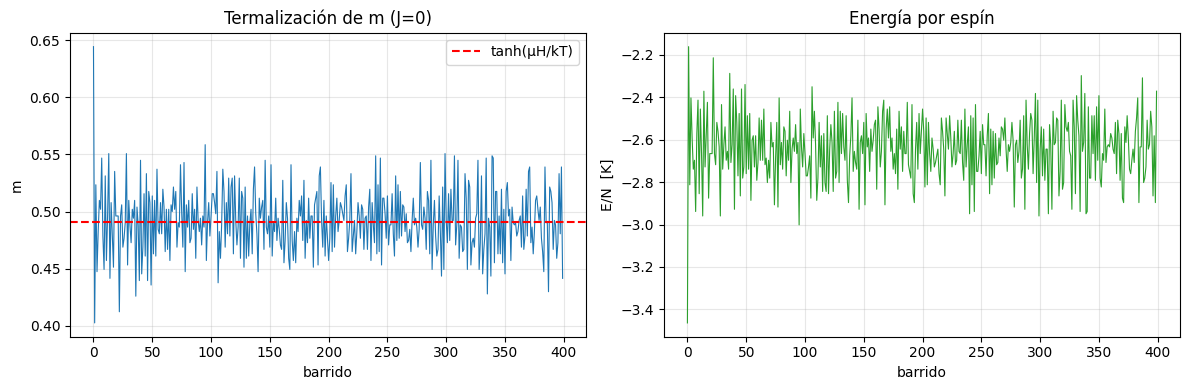

In [7]:
L = 32
T_test, H_test = 10.0, 8.0
masks = mascaras_tablero(L)
s = rng.choice([-1, 1], size=(L, L))
m_hist, e_hist = [], []
for _ in range(400):
    barrido_metropolis(s, T_test, H_test, 0.0, masks)
    m_hist.append(s.mean()); e_hist.append(energia(s, 0.0, H_test))

m_exacta = np.tanh(MU_K * H_test / T_test)
print(f"<m> MC (barridos 100-400) = {np.mean(m_hist[100:]):.4f}   exacta tanh = {m_exacta:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(m_hist, lw=0.8); ax[0].axhline(m_exacta, c="r", ls="--", label="tanh(μH/kT)")
ax[0].set_xlabel("barrido"); ax[0].set_ylabel("m"); ax[0].legend(); ax[0].set_title("Termalización de m (J=0)")
ax[1].plot(e_hist, lw=0.8, c="tab:green"); ax[1].set_xlabel("barrido"); ax[1].set_ylabel("E/N  [K]")
ax[1].set_title("Energía por espín"); plt.tight_layout(); plt.show()

Tras unos pocos barridos el sistema se estabiliza y fluctúa alrededor del valor exacto; usamos 200 barridos de
termalización y 600 de medición, más que suficientes.

### Simulación principal: $\langle m\rangle$ vs $H$ para $T = 5, 10, 15$ K, $-30T < H < 30T$

In [8]:
L = 24
temperaturas = [5, 10, 15]
H_vals = np.linspace(-30, 30, 41)          # campo en Tesla
J_int = 1.0                                # acoplamiento [K]

resultados = {}                            # (J, T) -> (m_media, error)
t0 = time.time()
for J in [0.0, J_int]:
    for T in temperaturas:
        m_med, m_err = [], []
        for H in H_vals:
            _, serie, _ = simular(L, T, H, J)
            m_med.append(serie.mean())
            # error con bloques (las muestras consecutivas están correlacionadas)
            bloques = serie.reshape(20, -1).mean(axis=1)
            m_err.append(bloques.std(ddof=1) / np.sqrt(len(bloques)))
        resultados[(J, T)] = (np.array(m_med), np.array(m_err))
print(f"Tiempo total: {time.time() - t0:.1f} s")

Tiempo total: 66.0 s


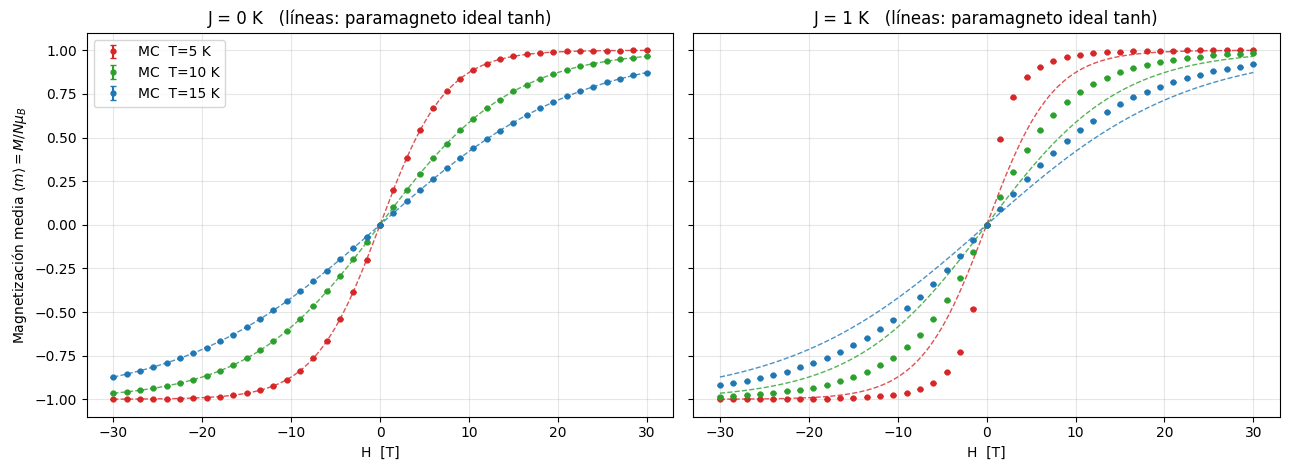

In [9]:
colores = {5: "tab:red", 10: "tab:green", 15: "tab:blue"}
H_fino = np.linspace(-30, 30, 400)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for k, J in enumerate([0.0, J_int]):
    for T in temperaturas:
        m, e = resultados[(J, T)]
        ax[k].errorbar(H_vals, m, yerr=e, fmt="o", ms=3.5, capsize=2, c=colores[T], label=f"MC  T={T} K")
        ax[k].plot(H_fino, np.tanh(MU_K * H_fino / T), "--", c=colores[T], lw=1, alpha=0.8)
    ax[k].set_xlabel("H  [T]"); ax[k].set_title(f"J = {J:g} K   (líneas: paramagneto ideal tanh)")
ax[0].set_ylabel(r"Magnetización media $\langle m\rangle = M/N\mu_B$")
ax[0].legend(); plt.tight_layout(); plt.show()

### Gráfica en función del campo reducido $H/T$

Para $J=0$ la teoría predice que $\langle m\rangle$ depende **sólo** de $H/T$, así que las tres curvas deben colapsar
en una sola. Con $J\neq0$ el colapso se rompe ligeramente: a menor $T$ la interacción ($J/T$) pesa más.

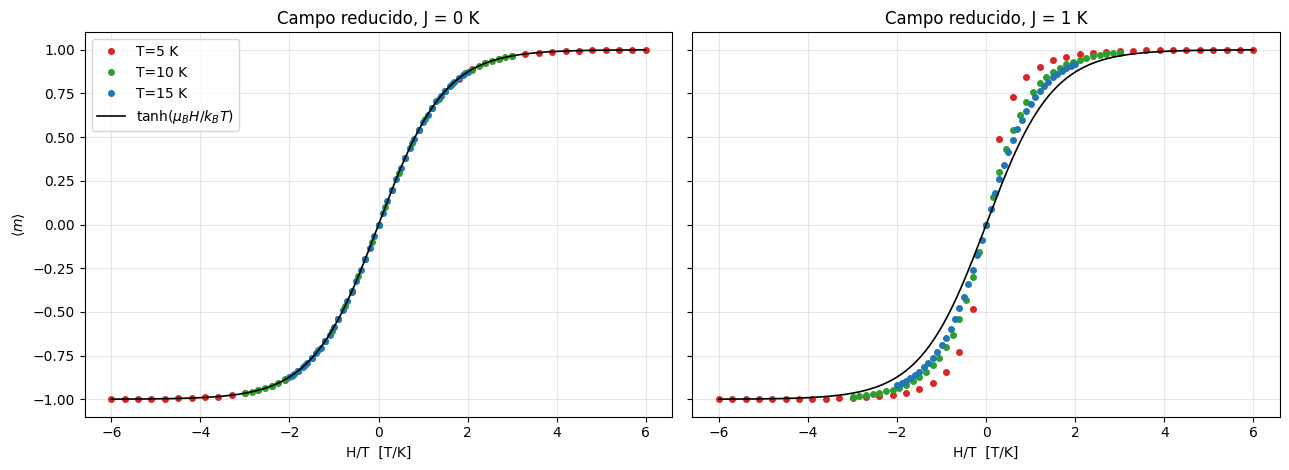

In [10]:
x = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for k, J in enumerate([0.0, J_int]):
    for T in temperaturas:
        m, _ = resultados[(J, T)]
        ax[k].plot(H_vals / T, m, "o", ms=4, c=colores[T], label=f"T={T} K")
    ax[k].plot(x, np.tanh(MU_K * x), "k-", lw=1.2, label=r"$\tanh(\mu_B H/k_BT)$")
    ax[k].set_xlabel("H/T  [T/K]"); ax[k].set_title(f"Campo reducido, J = {J:g} K")
ax[0].set_ylabel(r"$\langle m\rangle$"); ax[0].legend(); plt.tight_layout(); plt.show()

### Comparación con la aproximación de campo medio (con $J$)

En campo medio cada espín siente $J\,q\,m$ de sus $q=4$ vecinos más el campo externo:
$m = \tanh\!\left[\dfrac{qJm + (\mu_B/k_B)H}{T}\right]$, que resolvemos por iteración de punto fijo.

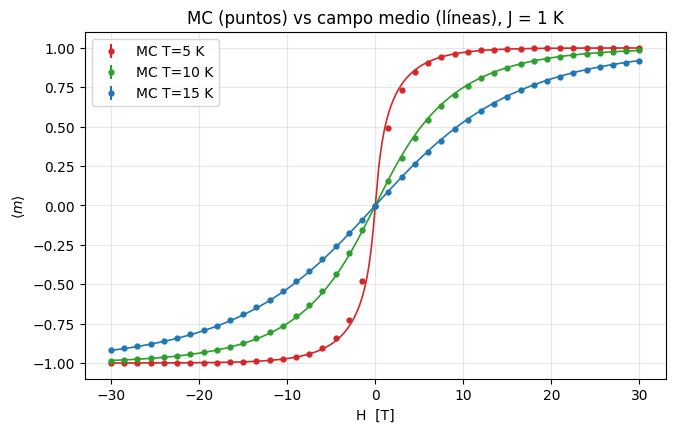

Diferencia RMS entre MC y teoría:
  T= 5 K:  J=0 vs tanh = 0.0005   |   J=1 K vs campo medio = 0.0238
  T=10 K:  J=0 vs tanh = 0.0007   |   J=1 K vs campo medio = 0.0069
  T=15 K:  J=0 vs tanh = 0.0009   |   J=1 K vs campo medio = 0.0038


In [11]:
def campo_medio(H, T, J, q=4, it=500):
    m = np.sign(H) + 1e-3
    for _ in range(it):
        m = np.tanh((q * J * m + MU_K * H) / T)
    return m

for T in temperaturas:
    m, e = resultados[(J_int, T)]
    plt.errorbar(H_vals, m, yerr=e, fmt="o", ms=3.5, c=colores[T], label=f"MC T={T} K")
    plt.plot(H_fino, campo_medio(H_fino, T, J_int), "-", c=colores[T], lw=1.2)
plt.xlabel("H  [T]"); plt.ylabel(r"$\langle m\rangle$")
plt.title(f"MC (puntos) vs campo medio (líneas), J = {J_int:g} K"); plt.legend(); plt.show()

print("Diferencia RMS entre MC y teoría:")
for T in temperaturas:
    m0, _ = resultados[(0.0, T)]; mJ, _ = resultados[(J_int, T)]
    r0 = np.sqrt(np.mean((m0 - np.tanh(MU_K * H_vals / T))**2))
    rJ = np.sqrt(np.mean((mJ - campo_medio(H_vals, T, J_int))**2))
    print(f"  T={T:>2} K:  J=0 vs tanh = {r0:.4f}   |   J=1 K vs campo medio = {rJ:.4f}")

### Configuraciones de espines

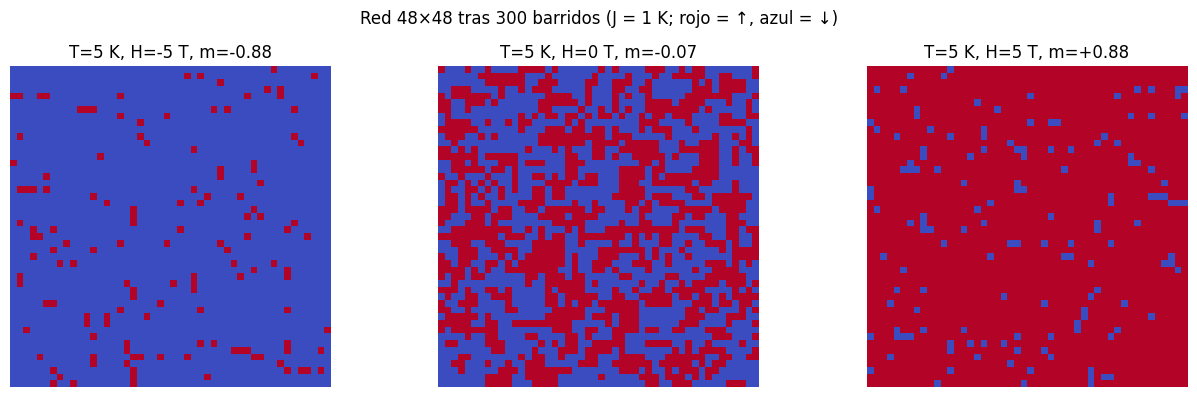

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a_, H in zip(ax, [-5, 0, 5]):
    s, serie, tasa = simular(48, 5, H, J_int, n_term=300, n_med=1)
    a_.imshow(s, cmap="coolwarm", vmin=-1, vmax=1)
    a_.set_title(f"T=5 K, H={H} T, m={s.mean():+.2f}"); a_.axis("off")
plt.suptitle(f"Red 48×48 tras 300 barridos (J = {J_int:g} K; rojo = ↑, azul = ↓)"); plt.tight_layout(); plt.show()

## Conclusiones

* La integración Monte Carlo reproduce $16/3$ y $2/3$ con error que decrece como $N^{-1/2}$; el estimador de valor medio
  es más eficiente que el de acierto–fallo.
* El algoritmo de Metrópolis con barrido de tablero de ajedrez visita todos los espines en cada paso y, para $J=0$,
  reproduce la ley exacta $\langle m\rangle=\tanh(\mu_B H/k_BT)$; las curvas de $T=5,10,15$ K colapsan al graficarlas contra $H/T$.
* La magnetización es impar en $H$, se satura en $\pm1$ para $|H|$ grande y la pendiente en el origen
  (susceptibilidad) crece al bajar la temperatura: $T=5$ K satura antes que $T=15$ K (ley de Curie, $\chi\propto1/T$).
* Con interacción de primeros vecinos ($J=1$ K) los espines se alinean más fácilmente y la saturación ocurre a campos
  menores. Como $T > T_c \approx 2.27$ K, no hay magnetización espontánea en $H=0$. El campo medio sobrestima el efecto
  de $J$ porque ignora las fluctuaciones locales; la diferencia es mayor a $T=5$ K, la más cercana a $T_c$.